# 05 — Analysis of the Models (2023–2025 data)
**Inputs:** `models/aqi_2023_25_best.pkl`, `data/Cleaned/aqi_2023_25_features.csv`, `data/Cleaned/predictions_2023_25_test.csv` (all produced by notebooks 03 and 04, so run those first).

Questions answered here:
1. Do the models actually beat "tomorrow = today"?
2. Which features matter? Do lags dominate, or does the calendar add something?
3. Where do the errors happen: which months, states, and Diwali days?
4. How do Delhi, Chandigarh and Mumbai perform (the project extension)?
5. Does the model do worse for cities with little data?

In [1]:
import sys, os, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score, f1_score, accuracy_score

from src.aqi_common import FEATURE_GROUPS, ALL_FEATURES, TRAIN_END, TEST_START, build_preprocessor

sns.set_style("whitegrid")
FIG = "../reports/figures/2023_25"
os.makedirs(FIG, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/2023_25_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

best = joblib.load("../models/aqi_2023_25_best.pkl")
clf, reg, labels = best['clf'], best['reg'], best['labels']
print("Classifier:", best['clf_name'], "| Regressor:", best['reg_name'], "| merge Severe:", best['merge_severe'])

feats = pd.read_csv("../data/Cleaned/aqi_2023_25_features.csv", parse_dates=['Date'])
preds = pd.read_csv("../data/Cleaned/predictions_2023_25_test.csv", parse_dates=['Date'])

def maybe_merge(s):
    return s.replace({'Very Poor': 'Very Poor/Severe', 'Severe': 'Very Poor/Severe'}) if best['merge_severe'] else s

feats['y_class'] = maybe_merge(feats['target_bucket_next'])
feats['today_class'] = maybe_merge(feats['AQI_Bucket'])

train = feats[feats['Date'] < TRAIN_END].reset_index(drop=True)
test = feats[feats['Date'] >= TEST_START].merge(
    preds[['City', 'Date', 'pred_class', 'pred_AQI']], on=['City', 'Date'], how='inner').reset_index(drop=True)

test['abs_err'] = (test['pred_AQI'] - test['target_AQI_next']).abs()
test['abs_err_persist'] = (test['AQI'] - test['target_AQI_next']).abs()
ord_ = {l: i for i, l in enumerate(labels)}
test['class_gap'] = (test['y_class'].map(ord_) - test['pred_class'].map(ord_)).abs()
print("Test rows:", len(test), "| train rows:", len(train))

Classifier: Random Forest | Regressor: Hist Gradient Boosting | merge Severe: False
Test rows: 31826 | train rows: 141433


## 1 — Do the models beat persistence?
*Skill* = how much of the persistence error the model removes. Positive means better than "tomorrow = today"; zero or negative means the model adds nothing.

In [2]:
mae_m, mae_p = test['abs_err'].mean(), test['abs_err_persist'].mean()
summary = pd.DataFrame({
    'Regression': ['MAE (model)', 'MAE (persistence)', 'Skill = 1 - MAE_model / MAE_persistence',
                   'R2 (model)'],
    'Value': [mae_m, mae_p, 1 - mae_m / mae_p, r2_score(test['target_AQI_next'], test['pred_AQI'])]})
print(summary.round(3).to_string(index=False))

f1_m = f1_score(test['y_class'], test['pred_class'], labels=labels, average='macro', zero_division=0)
f1_p = f1_score(test['y_class'], test['today_class'], labels=labels, average='macro', zero_division=0)
print("\nClassification")
print("macro-F1 model       :", round(f1_m, 3), "| accuracy:", round(accuracy_score(test['y_class'], test['pred_class']), 3))
print("macro-F1 persistence :", round(f1_p, 3), "| accuracy:", round(accuracy_score(test['y_class'], test['today_class']), 3))
print("Within one category  :", round((test['class_gap'] <= 1).mean(), 3))

                             Regression  Value
                            MAE (model) 23.505
                      MAE (persistence) 24.783
Skill = 1 - MAE_model / MAE_persistence  0.052
                             R2 (model)  0.728

Classification
macro-F1 model       : 0.584 | accuracy: 0.693
macro-F1 persistence : 0.592 | accuracy: 0.707
Within one category  : 0.988


**Takeaway:** *(be honest here. If persistence is hard to beat, say so: day-to-day AQI is very sticky, and the value of the model is in the harder cases below.)*

## 2 — Which features matter? (permutation importance)
Shuffle one feature at a time on the test data and see how much the score drops. Bigger drop = the model relies on it more. This works for any model and is measured on unseen data.

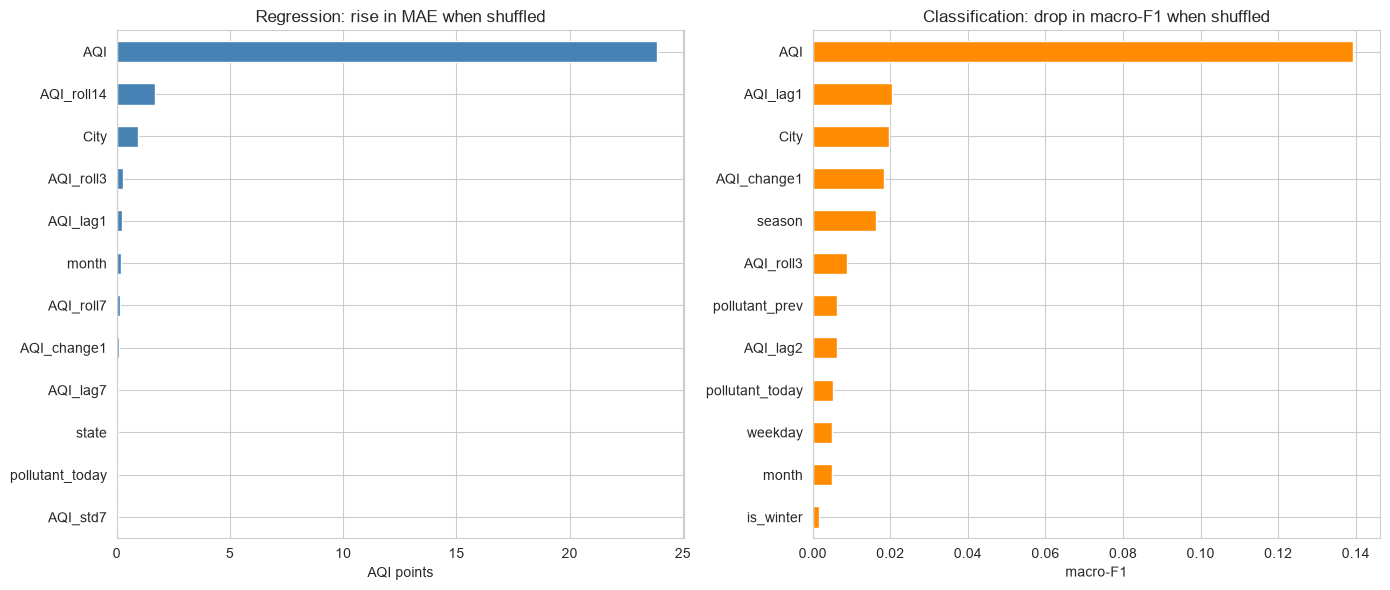

In [3]:
samp = test.sample(min(4000, len(test)), random_state=0)
Xs = samp[ALL_FEATURES]

pi_reg = permutation_importance(reg, Xs, samp['target_AQI_next'], scoring='neg_mean_absolute_error',
                                n_repeats=5, random_state=0, n_jobs=1)
pi_clf = permutation_importance(clf, Xs, samp['y_class'], scoring='f1_macro',
                                n_repeats=5, random_state=0, n_jobs=1)
imp_reg = pd.Series(pi_reg.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)
imp_clf = pd.Series(pi_clf.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
imp_reg.head(12).iloc[::-1].plot(kind='barh', ax=ax[0], color='steelblue')
ax[0].set_title("Regression: rise in MAE when shuffled"); ax[0].set_xlabel("AQI points")
imp_clf.head(12).iloc[::-1].plot(kind='barh', ax=ax[1], color='darkorange')
ax[1].set_title("Classification: drop in macro-F1 when shuffled"); ax[1].set_xlabel("macro-F1")
save("permutation_importance")

**Takeaway:** *(which features are on top? Features that are strongly correlated share their importance, so a low value does not always mean "useless".)*

## 3 — Importance by feature group
Adds up the importance of every feature in each group, to answer: do the lags dominate, or does the calendar add something?

          regression  classification
group                               
today           86.5            62.3
lags             1.3            10.7
rolling          7.7             3.6
calendar         0.8            11.1
context          0.4             4.6
city             3.4             7.7


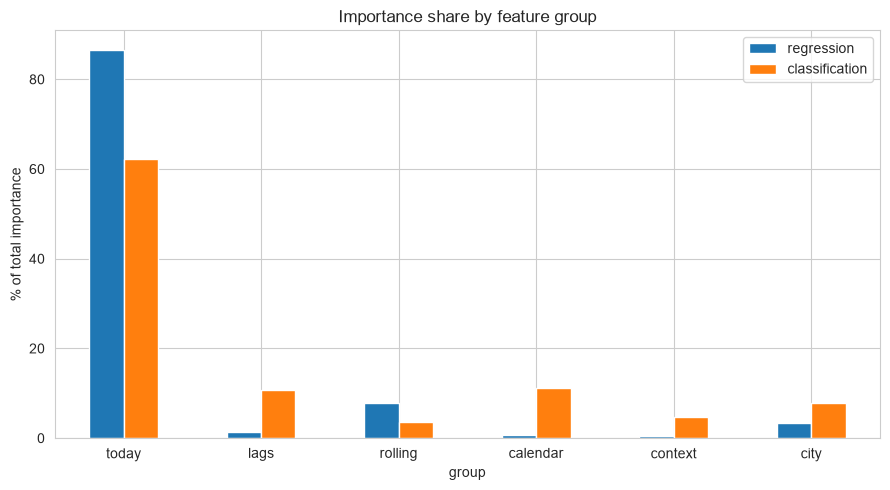

In [4]:
rows = []
for g, cols in FEATURE_GROUPS.items():
    rows.append({'group': g,
                 'regression': imp_reg.reindex(cols).clip(lower=0).sum(),
                 'classification': imp_clf.reindex(cols).clip(lower=0).sum()})
grp = pd.DataFrame(rows).set_index('group')
grp_pct = grp / grp.sum() * 100
print(grp_pct.round(1))

grp_pct.plot(kind='bar', figsize=(9, 5))
plt.ylabel("% of total importance"); plt.xticks(rotation=0)
plt.title("Importance share by feature group")
save("importance_by_group")

## 4 — Ablation: what does each group add?
Retrain a gradient boosting model with feature groups added step by step. If the error barely changes when a group is added, that group is not worth keeping.

In [5]:
steps = [('today + lags + rolling', ['today', 'lags', 'rolling']),
         ('+ calendar', ['today', 'lags', 'rolling', 'calendar']),
         ('+ context', ['today', 'lags', 'rolling', 'calendar', 'context']),
         ('+ city', ['today', 'lags', 'rolling', 'calendar', 'context', 'city'])]

abl = []
for name, groups in steps:
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    r = Pipeline([('pre', build_preprocessor(cols)), ('m', HistGradientBoostingRegressor(random_state=0))])
    r.fit(train[cols], train['target_AQI_next'])
    c = Pipeline([('pre', build_preprocessor(cols)),
                  ('m', HistGradientBoostingClassifier(class_weight='balanced', random_state=0))])
    c.fit(train[cols], train['y_class'])
    abl.append({'features': name,
                'MAE': mean_absolute_error(test['target_AQI_next'], r.predict(test[cols])),
                'macro-F1': f1_score(test['y_class'], c.predict(test[cols]), labels=labels,
                                     average='macro', zero_division=0)})
abl = pd.DataFrame(abl)
print("Persistence MAE for reference:", round(mae_p, 2))
abl.round(3)

Persistence MAE for reference: 24.78


,features,MAE,macro-F1
0,today + lags + rolling,23.422,0.577
1,+ calendar,23.579,0.576
2,+ context,23.477,0.574
3,+ city,23.520,0.582


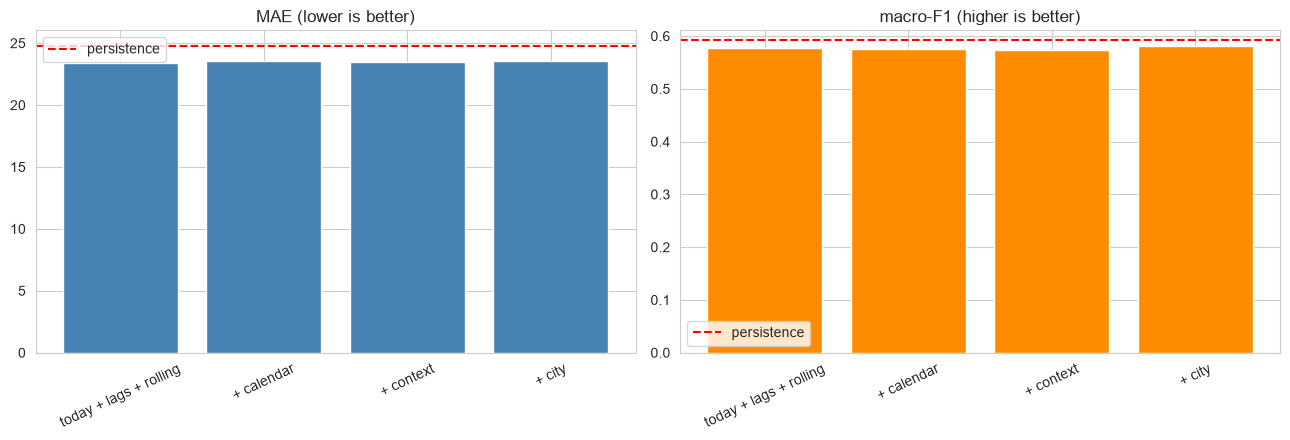

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(abl['features'], abl['MAE'], color='steelblue'); ax[0].axhline(mae_p, color='red', ls='--', label='persistence')
ax[0].set_title("MAE (lower is better)"); ax[0].legend(); ax[0].tick_params(axis='x', rotation=25)
ax[1].bar(abl['features'], abl['macro-F1'], color='darkorange'); ax[1].axhline(f1_p, color='red', ls='--', label='persistence')
ax[1].set_title("macro-F1 (higher is better)"); ax[1].legend(); ax[1].tick_params(axis='x', rotation=25)
save("ablation")

**Takeaway:** *(does the calendar add anything on top of the lags? Does adding city information help or just add noise?)*

## 5 — Errors by month
Test months run from November to April, covering the worst winter pollution.

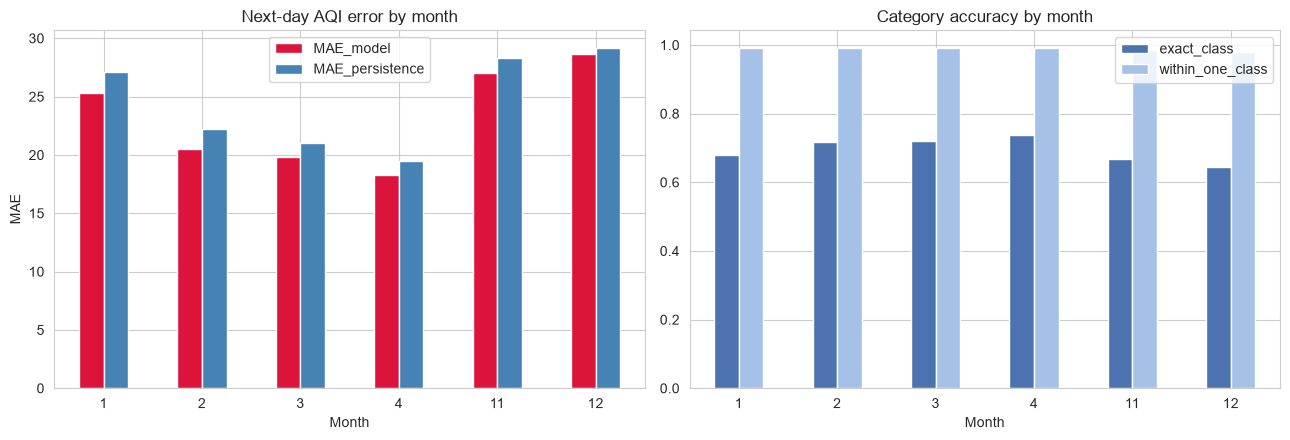

,rows,MAE_model,MAE_persistence,within_one_class,exact_class
Date,,,,,
1,4566,25.331,27.145,0.990,0.680
2,5009,20.499,22.267,0.992,0.717
3,5435,19.784,21.065,0.993,0.722
4,4806,18.322,19.480,0.992,0.737
11,6213,27.048,28.298,0.986,0.668
12,5797,28.651,29.210,0.979,0.644


In [7]:
by_month = test.groupby(test['Date'].dt.month).agg(
    rows=('abs_err', 'size'),
    MAE_model=('abs_err', 'mean'),
    MAE_persistence=('abs_err_persist', 'mean'),
    within_one_class=('class_gap', lambda s: (s <= 1).mean()),
    exact_class=('class_gap', lambda s: (s == 0).mean()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
by_month[['MAE_model', 'MAE_persistence']].plot(kind='bar', ax=ax[0], color=['crimson', 'steelblue'])
ax[0].set_title("Next-day AQI error by month"); ax[0].set_xlabel("Month"); ax[0].set_ylabel("MAE"); ax[0].tick_params(axis='x', rotation=0)
by_month[['exact_class', 'within_one_class']].plot(kind='bar', ax=ax[1], color=['#4c72b0', '#a6c1e8'])
ax[1].set_title("Category accuracy by month"); ax[1].set_xlabel("Month"); ax[1].tick_params(axis='x', rotation=0)
save("error_by_month")
by_month.round(3)

## 6 — Errors by state (the 12 states with most test rows)

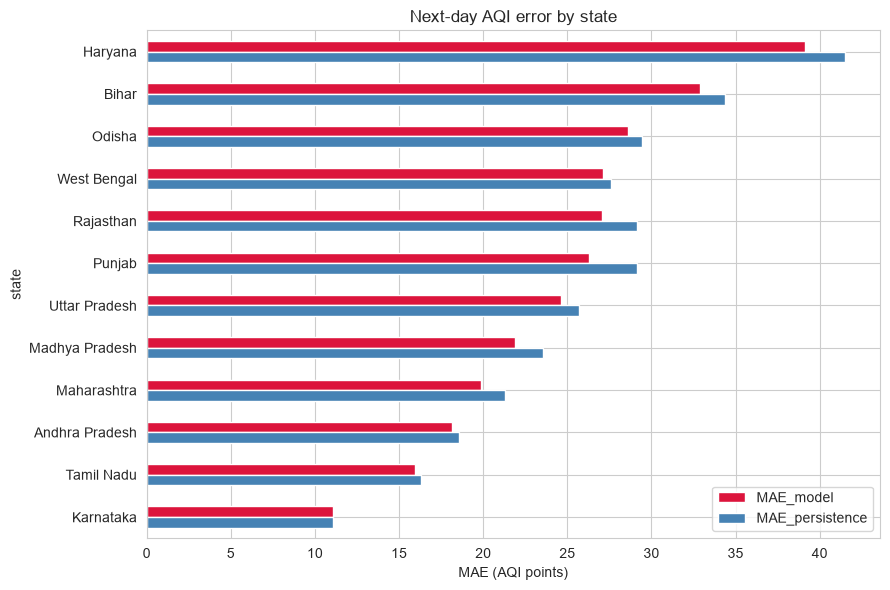

,rows,MAE_model,MAE_persistence
state,,,
Haryana,1110,39.15,41.51
Bihar,2278,32.88,34.36
Odisha,1751,28.61,29.44
West Bengal,1132,27.12,27.57
Rajasthan,5096,27.05,29.12
Punjab,1080,26.31,29.14
Uttar Pradesh,3187,24.63,25.69
Madhya Pradesh,2196,21.91,23.58
Maharashtra,4334,19.86,21.28


In [8]:
top_states = test['state'].value_counts().head(12).index
by_state = (test[test['state'].isin(top_states)].groupby('state')
            .agg(rows=('abs_err', 'size'), MAE_model=('abs_err', 'mean'), MAE_persistence=('abs_err_persist', 'mean'))
            .sort_values('MAE_model', ascending=False))
by_state[['MAE_model', 'MAE_persistence']].plot(kind='barh', figsize=(9, 6), color=['crimson', 'steelblue'])
plt.gca().invert_yaxis(); plt.xlabel("MAE (AQI points)"); plt.title("Next-day AQI error by state")
save("error_by_state")
by_state.round(2)

## 7 — Festival (Diwali) days vs the rest
The flag marks Diwali ±3 days. In the test period only the days from 1 Nov 2024 onward are inside the window, so the sample is small; treat it as an indication, not proof.

In [9]:
fest = test.groupby('is_festival').agg(
    rows=('abs_err', 'size'), MAE_model=('abs_err', 'mean'), MAE_persistence=('abs_err_persist', 'mean'),
    exact_class=('class_gap', lambda s: (s == 0).mean()))
fest.index = fest.index.map({0: 'normal days', 1: 'Diwali +-3 days'})
fest.round(3)

,rows,MAE_model,MAE_persistence,exact_class
is_festival,,,,
normal days,30962,23.292,24.587,0.693
Diwali +-3 days,864,31.144,31.807,0.670


## 8 — Delhi, Chandigarh and Mumbai (project extension)

In [10]:
wanted = ['Delhi', 'Chandigarh', 'Mumbai']
present = [c for c in wanted if c in set(test['City'])]
print("In the test data:", present, "| missing:", [c for c in wanted if c not in present])

rows = []
for c in present:
    s = test[test['City'] == c]
    rows.append({'City': c, 'test rows': len(s),
                 'MAE model': s['abs_err'].mean(), 'MAE persistence': s['abs_err_persist'].mean(),
                 'R2': r2_score(s['target_AQI_next'], s['pred_AQI']),
                 'exact category': (s['class_gap'] == 0).mean(),
                 'within one category': (s['class_gap'] <= 1).mean()})
city_tbl = pd.DataFrame(rows).set_index('City') if rows else pd.DataFrame()
city_tbl.round(3)

In the test data: ['Delhi', 'Chandigarh', 'Mumbai'] | missing: []


,test rows,MAE model,MAE persistence,R2,exact category,within one category
City,,,,,,
Delhi,174,34.624,35.891,0.749,0.557,0.966
Chandigarh,174,28.510,31.006,0.780,0.626,0.994
Mumbai,174,13.374,14.379,0.751,0.879,1.000


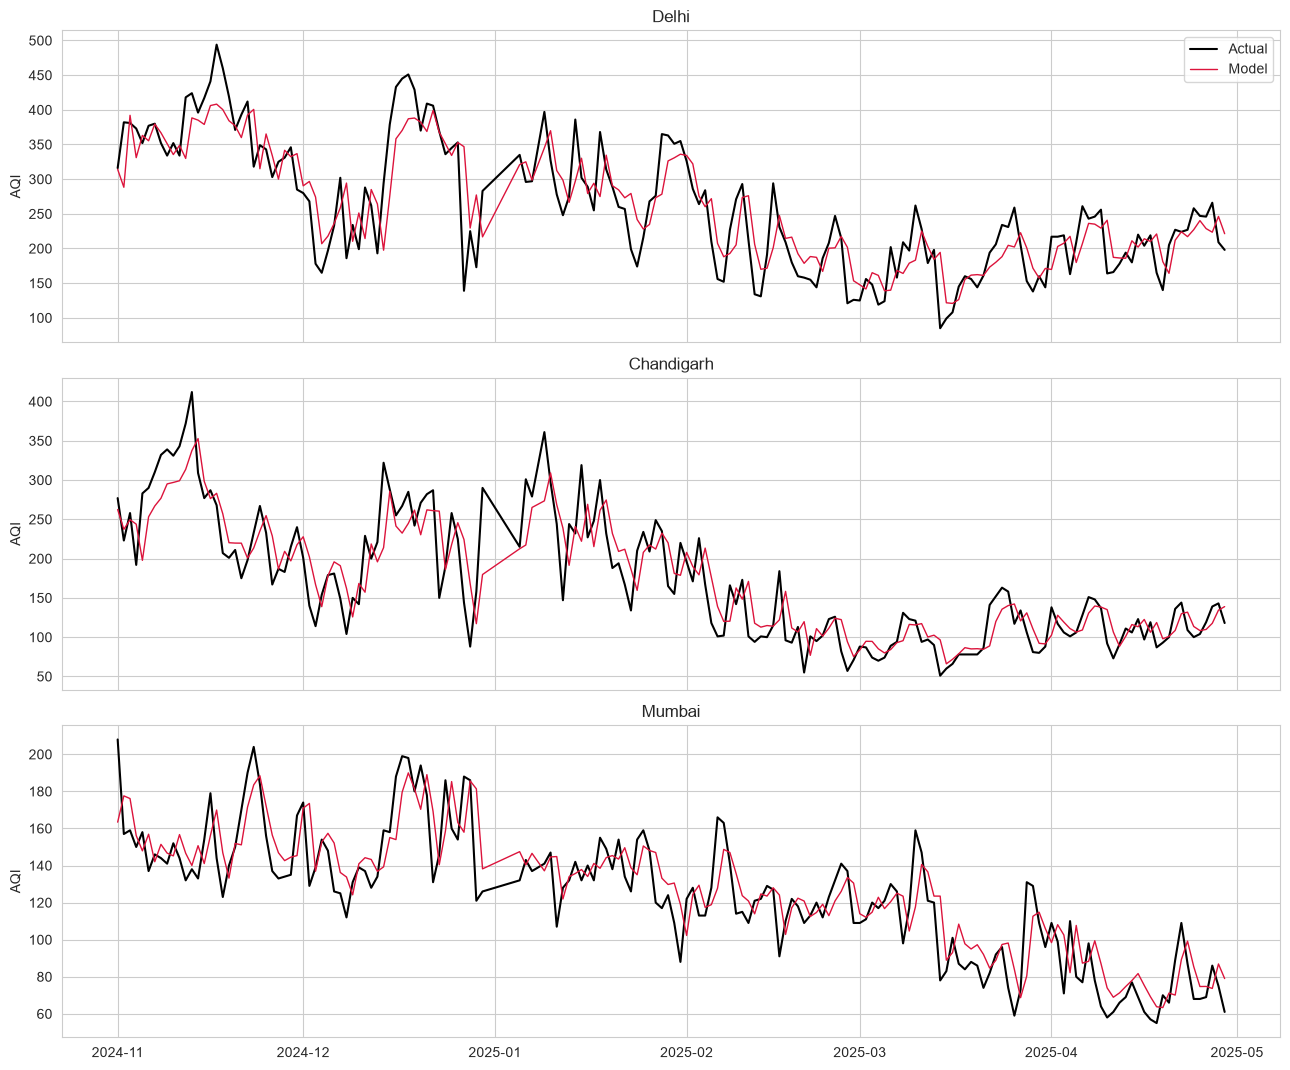

In [11]:
if present:
    fig, axes = plt.subplots(len(present), 1, figsize=(13, 3.6 * len(present)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, present):
        s = test[test['City'] == c].sort_values('Date')
        ax.plot(s['Date'], s['target_AQI_next'], color='black', label='Actual')
        ax.plot(s['Date'], s['pred_AQI'], color='crimson', lw=1, label='Model')
        ax.set_title(c); ax.set_ylabel("AQI")
    axes[0].legend()
    save("city_focus")

**Takeaway:** *(which of the three cities is easiest to forecast, and which is hardest? Link it back to your EDA: more volatile cities are harder.)*

## 9 — Does the model struggle where there is little data?
Compares each city's number of training days with its test error. Your data-quality block in the EDA already identified cities with few days.

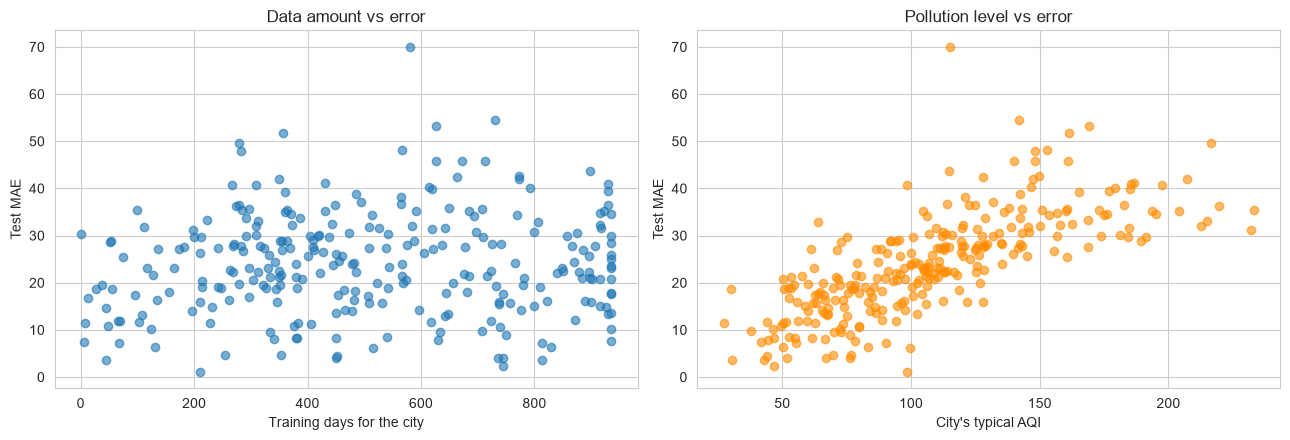

Spearman correlation, training days vs MAE      : 0.061
Spearman correlation, typical AQI vs MAE        : 0.81


In [12]:
per_city = pd.DataFrame({'train_days': train.groupby('City').size(),
                         'test_MAE': test.groupby('City')['abs_err'].mean(),
                         'test_MAE_persistence': test.groupby('City')['abs_err_persist'].mean(),
                         'city_mean_AQI': train.groupby('City')['AQI'].mean()}).dropna()
per_city['skill'] = 1 - per_city['test_MAE'] / per_city['test_MAE_persistence']

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(per_city['train_days'], per_city['test_MAE'], alpha=0.6)
ax[0].set_xlabel("Training days for the city"); ax[0].set_ylabel("Test MAE"); ax[0].set_title("Data amount vs error")
ax[1].scatter(per_city['city_mean_AQI'], per_city['test_MAE'], alpha=0.6, color='darkorange')
ax[1].set_xlabel("City's typical AQI"); ax[1].set_ylabel("Test MAE"); ax[1].set_title("Pollution level vs error")
save("data_amount_vs_error")

print("Spearman correlation, training days vs MAE      :", round(per_city['train_days'].corr(per_city['test_MAE'], method='spearman'), 3))
print("Spearman correlation, typical AQI vs MAE        :", round(per_city['city_mean_AQI'].corr(per_city['test_MAE'], method='spearman'), 3))

**Takeaway:** *(a clear negative correlation in the first number means cities with less data are forecast worse. Higher-AQI cities usually have larger absolute errors simply because their values are larger.)*

## 10 — The 15 worst predictions
Look at these by hand. They are usually sudden jumps (a festival, a weather change) that no feature available today could predict.

In [13]:
worst = test.nlargest(15, 'abs_err')[['City', 'state', 'Date', 'AQI', 'target_AQI_next', 'pred_AQI', 'abs_err']]
worst.round(1).reset_index(drop=True)

,City,state,Date,AQI,target_AQI_next,pred_AQI,abs_err
0,Agartala,Tripura,2025-04-26,24.0,333.0,58.3,274.7
1,Agartala,Tripura,2025-04-21,23.0,312.0,43.9,268.1
2,Agartala,Tripura,2025-04-04,36.0,314.0,50.7,263.3
3,Noida,Uttar Pradesh,2024-12-27,329.0,88.0,329.1,241.1
4,Gurugram,Haryana,2024-12-27,349.0,94.0,331.6,237.6
5,Nalbari,Assam,2025-02-08,118.0,384.0,148.7,235.3
6,Agartala,Tripura,2025-04-24,339.0,28.0,263.0,235.0
7,Delhi,Delhi,2024-12-27,353.0,139.0,346.9,207.9
8,Tiruchirappalli,Tamil Nadu,2025-03-16,197.0,318.0,114.1,203.9
9,Dholpur,Rajasthan,2024-11-17,80.0,300.0,99.4,200.6


---
# Wrap-up checklist

## Compare with the 2015–2020 results (`city_day.csv`)
Write one line each in your report:
- [ ] Seasonality: winter peak in both periods?
- [ ] PM2.5 / PM10 dominance: consistent between the two datasets?
- [ ] Most and least polluted cities: same ones?
- [ ] Persistence strength: did the 2015–2020 models also struggle to beat it?

## README and report
- [ ] Update the README results table with the numbers from `reports/results_*_2023_25.csv`.
- [ ] Tick the roadmap checkboxes you have completed.
- [ ] Report sections: problem, data, EDA findings, features, models, results versus baseline, limitations.

**Limitations to state:** no pollutant concentrations in this file, only about 2.3 years of data, a single test winter, rare classes (Good and Severe) with very few test examples so their scores are noisy, and the best model was chosen using the test period, which slightly flatters it.


